In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel('/content/drive/MyDrive/patient_records_dataset.xlsx')

df.head()

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
0,PAT-1001,1946-03-17,Male,166.5,80.2,O+,164,97,113.0,244.7,13.2,0,Non-Smoker,1
1,PAT-1002,1992-05-08,Female,156.8,57.8,O+,137,85,97.6,178.5,9.5,1,Non-Smoker,1
2,PAT-1003,1976-04-11,Female,165.9,85.9,O+,143,81,107.5,184.8,12.1,3,Non-Smoker,1
3,PAT-1004,1980-03-03,Female,153.7,69.6,A+,136,82,107.1,225.2,6.7,2,Non-Smoker,0
4,PAT-1005,1996-10-27,Male,180.9,89.0,O+,143,85,104.0,174.4,8.0,10,Former Smoker,1


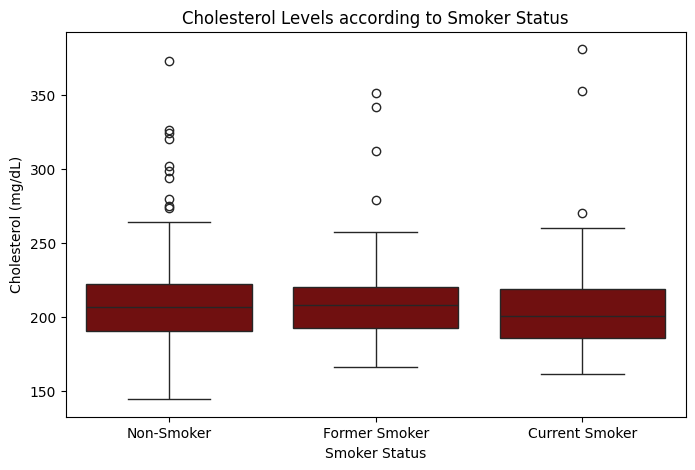

In [5]:
# Cholesterol box plot grouped by smoker status

plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='smoker_status', y='cholesterol_mg_dl', color='maroon')

plt.title('Cholesterol Levels according to Smoker Status')
plt.xlabel('Smoker Status')
plt.ylabel('Cholesterol (mg/dL)')
plt.show()

In [8]:
#Calculate upper whisker and extreme outliers
# IQR = Q3 − Q1
# Upper fence = Q3 + (1.5 × IQR)
# Upper whisker = highest actual value below or equal to the upper fence.

for status in df['smoker_status'].dropna().unique():

    data = df[df['smoker_status'] == status]['cholesterol_mg_dl'].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    upper_fence = Q3 + (1.5 * IQR)

    upper_whisker = data[data <= upper_fence].max()

    outliers = data[data > upper_fence]

    median = data.median()

    print("Smoker Status:", status)
    print("Median:", median)
    print("Upper Whisker:", upper_whisker)
    print("Upper Fence:", upper_fence)
    print("Extreme Outliers:", len(outliers))
    print("-------------------------")

Smoker Status: Non-Smoker
Median: 206.7
Upper Whisker: 264.2
Upper Fence: 269.65
Extreme Outliers: 10
-------------------------
Smoker Status: Former Smoker
Median: 208.1
Upper Whisker: 257.2
Upper Fence: 261.40000000000003
Extreme Outliers: 4
-------------------------
Smoker Status: Current Smoker
Median: 200.85
Upper Whisker: 260.1
Upper Fence: 268.34999999999997
Extreme Outliers: 3
-------------------------


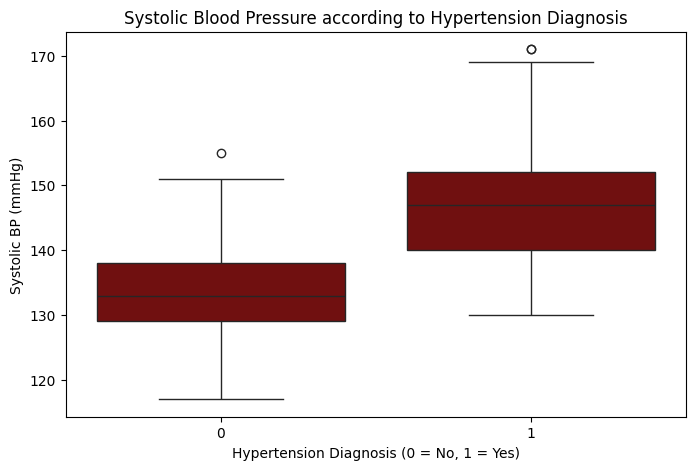

In [14]:
#Side-by-side box plots for systolic blood pressure

plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='hypertension_diagnosis', y='systolic_bp_mmHg', color='maroon')

plt.title('Systolic Blood Pressure according to Hypertension Diagnosis')
plt.xlabel('Hypertension Diagnosis (0 = No, 1 = Yes)')
plt.ylabel('Systolic BP (mmHg)')
plt.show()

In [16]:
#Calculate the median and quartiles

df.groupby('hypertension_diagnosis')['systolic_bp_mmHg'].describe()

,count,mean,std,min,25%,50%,75%,max
hypertension_diagnosis,,,,,,,,
0,105.0,133.390476,7.33340,117.0,129.0,133.0,138.0,155.0
1,395.0,146.982278,8.51378,130.0,140.0,147.0,152.0,171.0


In [3]:
# Correlation  Analysis
# identify which numerical factors are associated with hypertension

correlation = df.corr(numeric_only=True)

correlation['hypertension_diagnosis'].sort_values(ascending=False)

,hypertension_diagnosis
hypertension_diagnosis,1.000000
diastolic_bp_mmHg,0.601240
systolic_bp_mmHg,0.556530
fasting_blood_sugar_mg_dl,0.320622
cholesterol_mg_dl,0.223037
weight_kg,0.182054
daily_salt_intake_g,0.161014
activity_hours_per_week,0.033827
height_cm,-0.075089


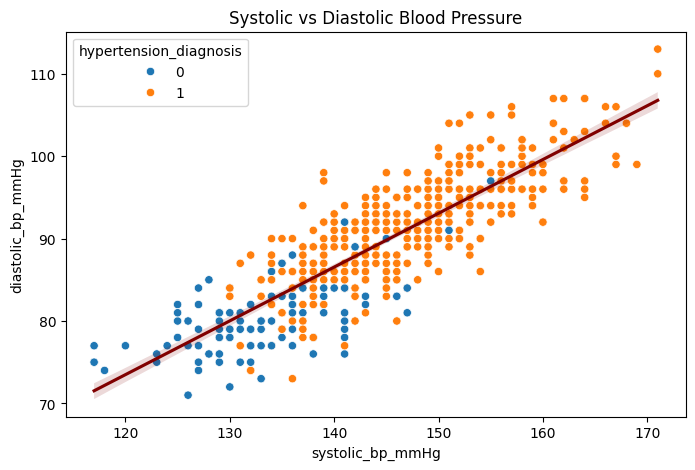

In [8]:
# Scatter plot: Systolic vs Diastolic BP

plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='systolic_bp_mmHg',
                y='diastolic_bp_mmHg',
                hue='hypertension_diagnosis')

sns.regplot(data=df, x='systolic_bp_mmHg',
            y='diastolic_bp_mmHg',
            scatter=False, color='maroon')

plt.title('Systolic vs Diastolic Blood Pressure')
plt.show()


In [14]:
# Supervised learning preparation
# We want to predict hypertension using numerical variables.
# X (features): Age, systolic BP, diastolic BP, cholesterol and blood sugar. y (target): Hypertension diagnosis.

X = df[['systolic_bp_mmHg',
        'diastolic_bp_mmHg',
        'cholesterol_mg_dl',
        'fasting_blood_sugar_mg_dl']]

y = df['hypertension_diagnosis']
X.head(10)

,systolic_bp_mmHg,diastolic_bp_mmHg,cholesterol_mg_dl,fasting_blood_sugar_mg_dl
0,164,97,244.7,113.0
1,137,85,178.5,97.6
2,143,81,184.8,107.5
3,136,82,225.2,107.1
4,143,85,174.4,104.0
5,161,102,210.9,107.5
6,152,91,231.1,108.0
7,137,78,195.5,109.0
8,148,91,257.2,122.8
9,147,92,185.2,107.0
